<a href="https://colab.research.google.com/github/FarahMandili/Firstcode_NN/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch #Library
import torch.nn as nn #Build neural network layers
import torch.optim as optim #Update model weights during training
import torchvision #Image datasets and vision tools
import torchvision.transforms as transforms #Preprocess images
from torch.utils.data import DataLoader #Load data in batches

In [2]:
transform = transforms.Compose([ #Convert the image (0-255) into a tensor (0-1) and normalize the tensor values
    transforms.ToTensor(), #change the image format into a tensor with dimensions (c,h,w)
    transforms.Normalize((0.1307,), (0.3081,)) #Normalises the tensor using the specified mean and standard deviation
])

In [3]:
train_dataset= torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset= torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 61.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.68MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]


In [4]:
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True) #learn and update weights
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False) # evaluate performance
# batch_size= how many images per batch will be involved
# shuffle= random rearrange the data at the start of each epoch or not

In [5]:
class ConvertedtoCNN(nn.Module): # create a nn class #change the class name and convert nn to cnn, chang it everywhere down
        def __init__(self): #Initialize the model's layers and components
          super(ConvertedtoCNN, self).__init__() #Initializes the parent nn.Modu1e

          # Convolutional Block 1
          self.conv1 = nn.Conv2d(in_channels= 1, out_channels= 28, kernel_size= 3, padding=1)
          self.relu1 = nn.ReLU()
          self.pool1 = nn.MaxPool2d(kernel_size= 2)

          # Convolutional Block 2
          self.conv2 = nn.Conv2d(in_channels= 28, out_channels= 56 , kernel_size= 3, padding=1)
          self.relu2 = nn.ReLU()
          self.pool2 = nn.MaxPool2d(kernel_size= 2)

          # Flatten layer
          self.flatten = nn.Flatten()

          # Fully Connected Layers
          self.fc1 = nn.Linear(56 * 7 * 7, 10)
          #self.relu3 = nn.ReLU(): #Defines how input data moves through the network during the forward pass
            #you don't need this final ReLU because your output layer should return raw logits for CrossEntropyLoss

        def forward(self, x):
              #x = self.pool1(self.relu1(self.conv1(x)))
              x = self.conv1(x)
              x = self.relu1(x)
              x = self.pool1(x)

              x = self.conv2(x)
              x = self.relu2(x)
              x = self.pool2(x)

              x = self.flatten(x)
              x = self.fc1(x)
              return x #Return the 10 outputs, Logits

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using {device}')

model = ConvertedtoCNN().to(device)# it is only called __init__()

loss_function = nn.CrossEntropyLoss() #loss function measures how far the model's predictions are from the correct labels #SoftMax inside this function####
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #The learning rate controls the size Of the weight updates. If it is too large, training may become unstable; if too small, learning may be slow

Using cpu


In [7]:
for data, target in train_loader:

    data, target = data.to(device), target.to(device)

    optimizer.zero_grad()

    output = model(data)

    loss = loss_function(output, target)

    loss.backward()

    optimizer.step()

In [8]:

def train_epoch(model, train_loader, loss_function, optimizer, device):
    model.train()

    # Initialise variables
    running_loss = 0.0
    correct = 0
    total = 0

    # Training loop
    for data, target in train_loader:
        data = data.to(device)
        target = target.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        output = model(data)

        # Calculate loss
        loss = loss_function(output, target)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate training loss
        running_loss += loss.item() * data.size(0)

        # Calculate training accuracy
        predicted = output.argmax(dim=1)
        correct += (predicted == target).sum().item()
        total += target.size(0)

    # Average loss and accuracy
    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    return train_loss, train_accuracy


In [9]:
import matplotlib.pyplot as plt
import numpy as np

Training and validation history

In [10]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

In [11]:

def evaluate(model, val_loader, loss_function, device):
    model.eval()

    # Initialise validation variables
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = loss_function(outputs, targets)

            # Accumulate validation loss
            val_running_loss += loss.item() * inputs.size(0)

            # Calculate validation accuracy
            predicted = outputs.argmax(dim=1)
            val_correct += (predicted == targets).sum().item()
            val_total += targets.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    return val_loss, val_accuracy



In [12]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

num_epochs = 10

for epoch in range(num_epochs):

    train_loss, train_accuracy = train_epoch(
        model, train_loader, loss_function, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, test_loader, loss_function, device
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")


Epoch 1/10
Train Loss: 0.0551 | Train Accuracy: 98.26%
Val Loss: 0.0376 | Val Accuracy: 98.71%
Epoch 2/10
Train Loss: 0.0404 | Train Accuracy: 98.76%
Val Loss: 0.0366 | Val Accuracy: 98.73%
Epoch 3/10
Train Loss: 0.0312 | Train Accuracy: 99.05%
Val Loss: 0.0314 | Val Accuracy: 98.93%
Epoch 4/10
Train Loss: 0.0252 | Train Accuracy: 99.20%
Val Loss: 0.0288 | Val Accuracy: 99.01%
Epoch 5/10
Train Loss: 0.0211 | Train Accuracy: 99.33%
Val Loss: 0.0365 | Val Accuracy: 98.89%
Epoch 6/10
Train Loss: 0.0179 | Train Accuracy: 99.42%
Val Loss: 0.0350 | Val Accuracy: 98.77%
Epoch 7/10
Train Loss: 0.0153 | Train Accuracy: 99.47%
Val Loss: 0.0296 | Val Accuracy: 99.11%
Epoch 8/10
Train Loss: 0.0126 | Train Accuracy: 99.57%
Val Loss: 0.0329 | Val Accuracy: 98.95%
Epoch 9/10
Train Loss: 0.0102 | Train Accuracy: 99.70%
Val Loss: 0.0287 | Val Accuracy: 99.13%
Epoch 10/10
Train Loss: 0.0083 | Train Accuracy: 99.73%
Val Loss: 0.0265 | Val Accuracy: 99.25%


Minimum observed loss

In [13]:
train_min_loss = min(history["train_loss"])
val_min_loss = min(history["val_loss"])

train_min_epoch = np.argmin(history["train_loss"]) + 1
val_min_epoch = np.argmin(history["val_loss"]) + 1

print("Minimum training loss:", train_min_loss)
print("Minimum validation loss:", val_min_loss)

print("Best training epoch:", train_min_epoch)
print("Best validation epoch:", val_min_epoch)

Minimum training loss: 0.00827477560172168
Minimum validation loss: 0.026531900686677545
Best training epoch: 10
Best validation epoch: 10


Loss learning curve

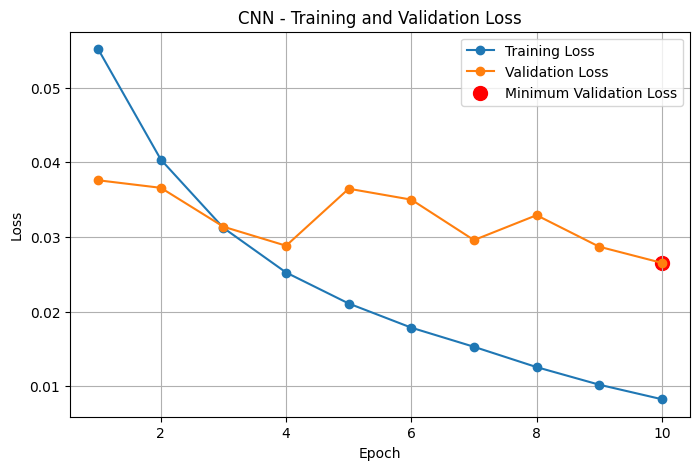

In [14]:
# Loss Learning Curve

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

# Highlight minimum validation loss
best_epoch = np.argmin(history["val_loss"]) + 1
best_loss = min(history["val_loss"])

plt.scatter(
    best_epoch,
    best_loss,
    color="red",
    s=100,
    label="Minimum Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN - Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig("cnn_loss_learning_curve.png", dpi=300)

plt.show()

Accuracy learning curve

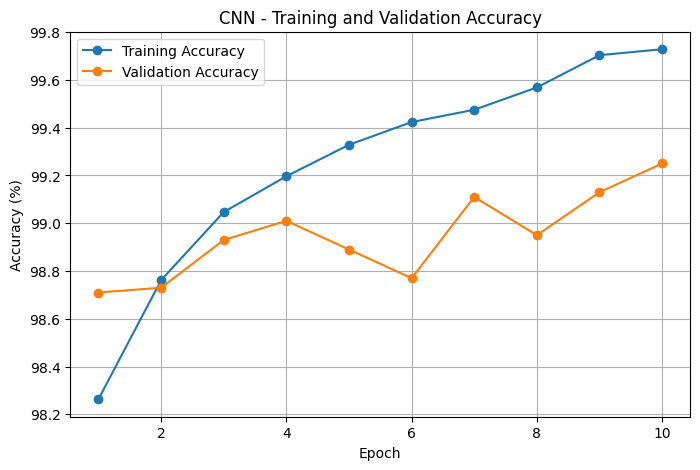

In [15]:
# Accuracy Learning Curve

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("CNN - Training and Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig("cnn_accuracy_learning_curve.png", dpi=300)

plt.show()

In [16]:
history["train_loss"].append(train_loss)
history["val_loss"].append(val_loss)

history["train_accuracy"].append(train_accuracy)
history["val_accuracy"].append(val_accuracy)

In [17]:
from os import pread
def train_epoch(model, train_loader, loss_function, optimizer, device):
    model.train() #the model is in training mode. This matters for layers such as dropout and batch normalisation
    running_loss = 0.0 #accumulates the loss over batches
    correct = 0 #counts correctly classified images
    total = 0 #counts the images processed

    for batch_idx, (data, target) in enumerate(train_loader):  #the batch number starting from 0
        data, target = data.to(device), target.to(device)#groundtruth==labels==target

    optimizer.zero_grad() #clear old gradients
    output = model(data) #forward pass it is called forward(self, x)
    #output = model.forward(data) #forward pass it is called forward(self, x)
    loss = loss_function(output, target) #calculate loss, smaller loss indicates better predictions
    loss.backward() #backpropagation
    optimizer.step() #update weights

    running_loss += loss.item()
    _, predicted = output.max(1) #finds the highest-scoring class for each image
    total += target.size(0) #gives the number of images in the batch
    correct += predicted.eq(target).sum().item() #counts the correct predictions

    if batch_idx % 100 == 0 and batch_idx > 0:
      avg_loss = running_loss / 100    #calculates the average loss across the last 100 batches
      accuracy = 100. * correct / total
      print(f'[{batch_idx *64}/{60000}]'
            f' Loss: {avg_loss:.3f} | Accuracy: {accuracy:.1f}%')
      running_loss = 0.0


# train_epoch(model, train_loader, loss_function, optimizer, device)


In [18]:
def evaluate(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad(): #no grad, no updating for the model's weights
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _,predicted = outputs.max(1) #selects the highest-scoring class for each image
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    return 100. * correct / total #Calculates the overall test accuracy as a percentage

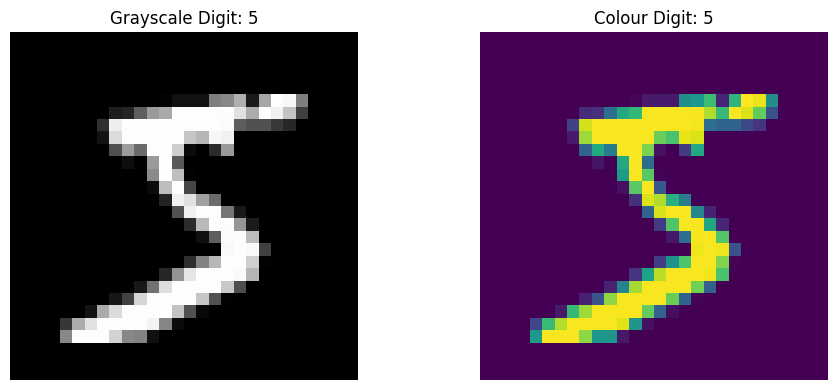

In [19]:

import matplotlib.pyplot as plt
import numpy as np

# Choose a digit from MNIST
image, label = train_dataset[0]

# Reverse the normalisation
image = image * 0.3081 + 0.1307
image = image.squeeze().numpy()

plt.figure(figsize=(10, 4))

# Grayscale
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"Grayscale Digit: {label}")
plt.axis("off")

# Colour
plt.subplot(1, 2, 2)
plt.imshow(image, cmap="viridis")
plt.title(f"Colour Digit: {label}")
plt.axis("off")

plt.tight_layout()
plt.show()


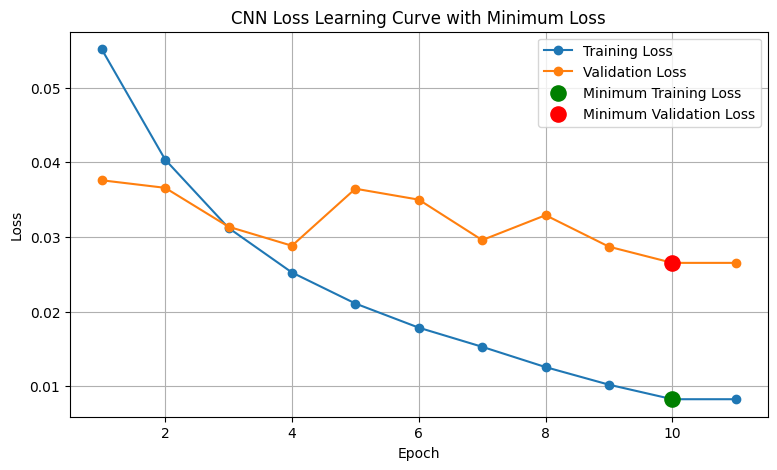

In [20]:

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_loss"],
         marker="o", label="Training Loss")

plt.plot(epochs, history["val_loss"],
         marker="o", label="Validation Loss")

# Highlight lowest observed training loss
plt.scatter(
    train_min_epoch, train_min_loss,
    color="green", s=120,
    label="Minimum Training Loss", zorder=5
)

# Highlight lowest observed validation loss
plt.scatter(
    val_min_epoch, val_min_loss,
    color="red", s=120,
    label="Minimum Validation Loss", zorder=5
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss Learning Curve with Minimum Loss")
plt.legend()
plt.grid(True)

plt.show()


In [21]:

print(f"Final Training Accuracy: {history['train_accuracy'][-1]:.2f}%")
print(f"Final Validation Accuracy: {history['val_accuracy'][-1]:.2f}%")

best_val_accuracy = max(history["val_accuracy"])
best_epoch = np.argmax(history["val_accuracy"]) + 1

print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")
print(f"At Epoch: {best_epoch}")


Final Training Accuracy: 99.73%
Final Validation Accuracy: 99.25%
Best Validation Accuracy: 99.25%
At Epoch: 10


F1 and balance accuracy

In [22]:

from sklearn.metrics import f1_score, balanced_accuracy_score, classification_report

# Set model to evaluation mode
model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for data, target in test_loader:
        data = data.to(device)
        target = target.to(device)

        # Forward pass
        output = model(data)

        # Get predicted classes
        predicted = output.argmax(dim=1)

        # Store predictions and actual labels
        all_predictions.extend(predicted.cpu().numpy())
        all_targets.extend(target.cpu().numpy())

# Calculate F1-score
f1 = f1_score(all_targets, all_predictions, average='macro')

# Calculate Balanced Accuracy
balanced_acc = balanced_accuracy_score(
    all_targets, all_predictions
)

print(f"F1-Score: {f1:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")

# Detailed classification results
print("\nClassification Report:")
print(classification_report(all_targets, all_predictions))


F1-Score: 0.9924
Balanced Accuracy: 0.9924

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.98      0.99      0.99       974
           9       1.00      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [23]:
best_val_accuracy = max(history["val_accuracy"])
best_epoch = np.argmax(history["val_accuracy"]) + 1

print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")
print(f"Best Epoch: {best_epoch}")

Best Validation Accuracy: 99.25%
Best Epoch: 10


In [24]:

# Best Training Accuracy
best_train_accuracy = max(history["train_accuracy"])
best_train_epoch = np.argmax(history["train_accuracy"]) + 1

# Best Validation Accuracy
best_val_accuracy = max(history["val_accuracy"])
best_val_epoch = np.argmax(history["val_accuracy"]) + 1

print(f"Best Training Accuracy: {best_train_accuracy:.2f}%")
print(f"Best Training Epoch: {best_train_epoch}")

print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")
print(f"Best Validation Epoch: {best_val_epoch}")


Best Training Accuracy: 99.73%
Best Training Epoch: 10
Best Validation Accuracy: 99.25%
Best Validation Epoch: 10
